# NLP-Based Sentiment Analysis of Customer Reviews

## Project Objective

This project analyzes Amazon-style customer reviews and classifies each review as **Negative, Neutral, or Positive**.

### What we will do

1. Load and understand the review dataset.
2. Explore ratings and review-text patterns.
3. Convert star ratings into sentiment labels.
4. Prepare the review text for NLP.
5. Apply **VADER** and **TextBlob** as lexicon-based sentiment baselines.
6. Split the data into training and testing sets.
7. Convert text into numerical features using **TF-IDF**.
8. Train and compare **5 supervised text-classification models**.
9. Evaluate the models using Accuracy, Precision, Recall, and F1 Score.
10. Perform error analysis.
11. Save the selected model and TF-IDF vectorizer for the Streamlit app.

> **Important:** Each section below explains **why we are doing it, what we are doing, and how it works**, so the notebook can also be used for interview/project explanation.


## 1. Data Loading & Understanding

### Why are we doing this?

Before building an NLP model, we need to understand what data we have, how many records exist, which columns contain useful information, and whether there are missing or duplicate records.

### What are we doing?

We load the Excel dataset and inspect:
- number of rows and columns
- column names and data types
- missing values
- duplicate rows

### Expected dataset columns

- `title` → review title
- `rating` → star rating from 1 to 5
- `body` → customer review text


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings

warnings.filterwarnings("ignore")

data = pd.read_excel("dataset.xlsx")

print("Dataset loaded successfully.")
print("Shape:", data.shape)
data.head()


Dataset loaded successfully.
Shape: (1440, 3)


,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance...
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp..."


In [2]:
print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])
print("\nColumns:", data.columns.tolist())


Number of rows: 1440
Number of columns: 3

Columns: ['title', 'rating', 'body']


In [3]:
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   title   1440 non-null   str  
 1   rating  1440 non-null   int64
 2   body    1440 non-null   str  
dtypes: int64(1), str(2)
memory usage: 508.5 KB


In [4]:
print("Missing values:")
display(data.isnull().sum())

print("\nDuplicate rows:", data.duplicated().sum())


Missing values:


title     0
rating    0
body      0
dtype: int64


Duplicate rows: 0


## 2. Exploratory Data Analysis (EDA)

### Why are we doing this?

EDA helps us understand the data before preprocessing and modeling. In a sentiment project, rating distribution and review length are useful because they show whether classes are balanced and how customers write reviews.

### What are we checking?

- Distribution of ratings
- Review length
- Average review length by rating

### How does this help?

These observations guide preprocessing and help us explain the dataset during an interview.


In [5]:
rating_counts = data["rating"].value_counts().sort_index()
display(rating_counts)


rating
1    386
2    126
3    199
4    310
5    419
Name: count, dtype: int64

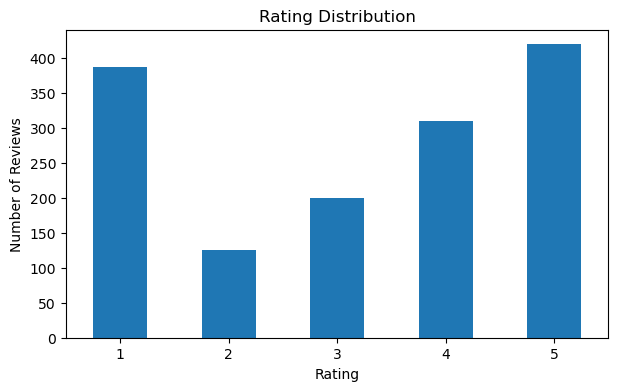

In [6]:
plt.figure(figsize=(7, 4))
rating_counts.plot(kind="bar")
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.show()


In [7]:
data["review_length"] = data["body"].fillna("").astype(str).str.len()

print("Review length summary:")
display(data["review_length"].describe())


Review length summary:


count    1440.000000
mean      302.109028
std       225.733052
min         4.000000
25%       170.000000
50%       246.000000
75%       359.000000
max      2490.000000
Name: review_length, dtype: float64

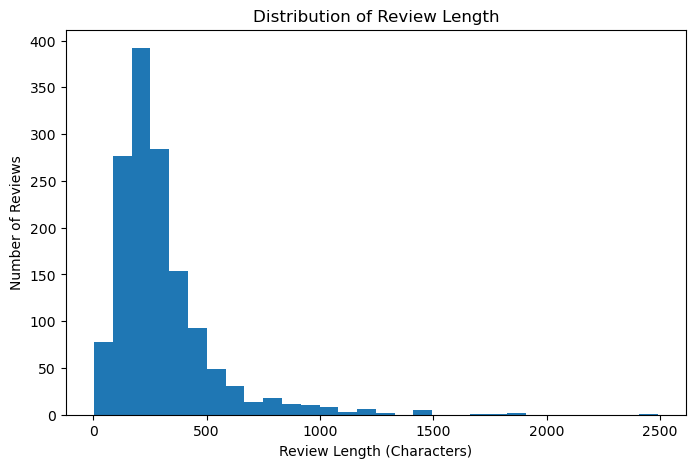

In [8]:
plt.figure(figsize=(8, 5))
plt.hist(data["review_length"], bins=30)
plt.title("Distribution of Review Length")
plt.xlabel("Review Length (Characters)")
plt.ylabel("Number of Reviews")
plt.show()


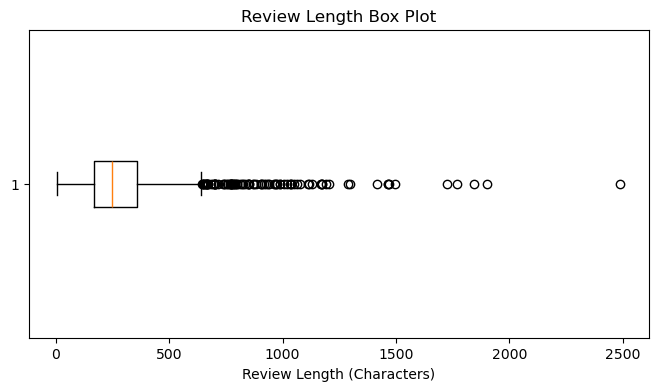

In [9]:
plt.figure(figsize=(8, 4))
plt.boxplot(data["review_length"], vert=False)
plt.title("Review Length Box Plot")
plt.xlabel("Review Length (Characters)")
plt.show()


In [10]:
rating_length = data.groupby("rating")["review_length"].mean()
display(rating_length)


rating
1    297.613990
2    294.920635
3    321.773869
4    321.245161
5    284.914081
Name: review_length, dtype: float64

## 3. Sentiment Labeling

### Why are we doing this?

The dataset contains **star ratings**, not a ready-made sentiment column. Machine-learning classification needs a target label, so we convert the ratings into three sentiment classes.

### Labeling rule

| Rating | Sentiment |
|---|---|
| 1–2 | Negative |
| 3 | Neutral |
| 4–5 | Positive |

### Why these groups?

Low ratings generally indicate dissatisfaction, 3 stars represents a neutral/mixed experience, and high ratings indicate satisfaction.

This target column will be used as `y` during supervised learning.


In [11]:
def assign_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

data["sentiment"] = data["rating"].apply(assign_sentiment)

display(data[["rating", "sentiment"]].head())
print("\nSentiment distribution:")
display(data["sentiment"].value_counts())


,rating,sentiment
0,1,Negative
1,3,Neutral
2,4,Positive
3,1,Negative
4,1,Negative



Sentiment distribution:


sentiment
Positive    729
Negative    512
Neutral     199
Name: count, dtype: int64

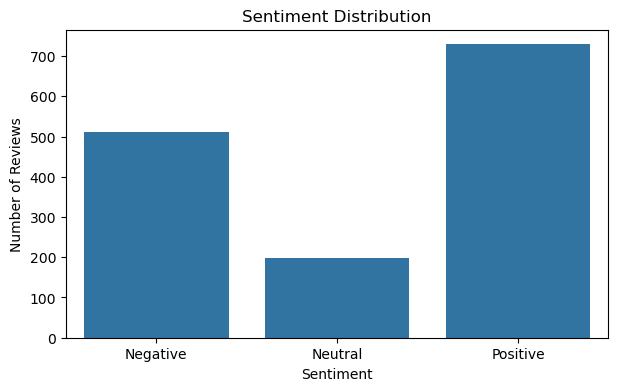

In [12]:
plt.figure(figsize=(7, 4))
sns.countplot(
    data=data,
    x="sentiment",
    order=["Negative", "Neutral", "Positive"]
)
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()


## 4. Text Preparation / Preprocessing

### Why are we doing this?

Raw customer reviews contain URLs, HTML tags, punctuation, numbers, inconsistent capitalization, and extra spaces. These can add noise to traditional text-classification models.

### What are we doing?

1. Combine `title` and `body` into one text field.
2. Convert text to lowercase.
3. Remove URLs.
4. Remove HTML tags.
5. Keep alphabetic characters and spaces.
6. Remove extra whitespace.

### Important design choice

We create **two versions**:
- `text` → original combined review text. This is used by VADER and TextBlob because their lexicons/rules can benefit from the original wording.
- `clean_text` → normalized text used for TF-IDF and ML models.

This prevents the VADER/TextBlob step from accidentally depending on a missing or incorrectly named `clean_text` column.


In [13]:
data["text"] = (
    data["title"].fillna("").astype(str)
    + " "
    + data["body"].fillna("").astype(str)
).str.strip()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

data["clean_text"] = data["text"].apply(clean_text)

display(data[["text", "clean_text"]].head())
print("Empty cleaned reviews:", (data["clean_text"].str.len() == 0).sum())


,text,clean_text
0,Horrible product Very disappointed with the ov...,horrible product very disappointed with the ov...
1,Camera quality is not like 48 megapixel Camera...,camera quality is not like megapixel camera qu...
2,"Overall Got the mobile on the launch date,Batt...",overall got the mobile on the launch date batt...
3,A big no from me 1. It doesn't work with 5.0GH...,a big no from me it doesn t work with ghz wifi...
4,Put your money somewhere else Not worth buying...,put your money somewhere else not worth buying...


Empty cleaned reviews: 2


## 5. VADER & TextBlob Sentiment Baselines

### Why are we doing this?

Before supervised machine learning, it is useful to establish a simple baseline using **lexicon-based sentiment analysis**.

### VADER

**VADER (Valence Aware Dictionary and sEntiment Reasoner)** uses a sentiment lexicon and rule-based heuristics. It produces a compound score between -1 and +1.

We map the score as:
- `>= 0.05` → Positive
- `<= -0.05` → Negative
- otherwise → Neutral

### TextBlob

TextBlob provides a simple polarity score:
- positive polarity → Positive
- negative polarity → Negative
- zero polarity → Neutral

### Why compare these with ML later?

VADER/TextBlob do not learn from our labeled dataset. TF-IDF + supervised models **learn patterns from our training reviews**, so comparing both approaches gives a clearer picture of the project.


In [14]:
# If this import fails, run:
# !{sys.executable} -m pip install vaderSentiment textblob

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from textblob import TextBlob

vader = SentimentIntensityAnalyzer()

def vader_sentiment(text):
    score = vader.polarity_scores(str(text))["compound"]
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    return "Neutral"

def textblob_sentiment(text):
    polarity = TextBlob(str(text)).sentiment.polarity
    if polarity > 0:
        return "Positive"
    elif polarity < 0:
        return "Negative"
    return "Neutral"

# Use the original combined text for lexicon methods.
data["vader_sentiment"] = data["text"].apply(vader_sentiment)
data["textblob_sentiment"] = data["text"].apply(textblob_sentiment)

display(
    data[
        ["text", "sentiment", "vader_sentiment", "textblob_sentiment"]
    ].head()
)


ModuleNotFoundError: No module named 'vaderSentiment'

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

lexicon_results = pd.DataFrame([
    {
        "Method": "VADER",
        "Accuracy": accuracy_score(data["sentiment"], data["vader_sentiment"]),
        "Precision": precision_score(
            data["sentiment"], data["vader_sentiment"],
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            data["sentiment"], data["vader_sentiment"],
            average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            data["sentiment"], data["vader_sentiment"],
            average="weighted", zero_division=0
        )
    },
    {
        "Method": "TextBlob",
        "Accuracy": accuracy_score(data["sentiment"], data["textblob_sentiment"]),
        "Precision": precision_score(
            data["sentiment"], data["textblob_sentiment"],
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            data["sentiment"], data["textblob_sentiment"],
            average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            data["sentiment"], data["textblob_sentiment"],
            average="weighted", zero_division=0
        )
    }
])

display(lexicon_results.round(4))


## 6. Train-Test Split

### Why are we doing this?

We need separate data for learning and final evaluation.

- **Training set (80%)** → used to learn patterns.
- **Test set (20%)** → kept unseen until evaluation.

### Why `stratify=y`?

Our target has three classes. Stratification keeps approximately the same Negative/Neutral/Positive proportions in both train and test sets.

### Important rule

We must not fit the TF-IDF vectorizer on the test set. Otherwise information from the test set can leak into training.


In [ ]:
from sklearn.model_selection import train_test_split

X = data["clean_text"]
y = data["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
display(y_train.value_counts())

print("Testing class distribution:")
display(y_test.value_counts())


## 7. TF-IDF Feature Extraction

### Why are we doing this?

Machine-learning algorithms cannot directly understand raw text. TF-IDF converts text into numerical features.

**TF-IDF = Term Frequency × Inverse Document Frequency**

- **TF** measures how often a term appears in a document.
- **IDF** reduces the importance of words that appear in many documents.
- The final value gives more weight to terms that are useful for distinguishing documents.

### What are we using?

- `ngram_range=(1, 2)` → unigrams + bigrams
- `max_features=10000` → limits feature count
- `min_df=2` → ignores extremely rare terms
- `max_df=0.95` → ignores extremely common terms
- `sublinear_tf=True` → uses a logarithmic term-frequency scaling

### Critical ML practice

`fit_transform()` is used only on `X_train`.

`transform()` is used on `X_test`.

This avoids test-set information leakage.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Number of learned features:", len(tfidf.get_feature_names_out()))


## 8. Model Building — 5 Text Classification Models

### Why are we doing this?

There is no single model that is always best for every text dataset. We therefore train multiple algorithms on the **same TF-IDF features** and compare them using the same test set.

### Five models

1. **Logistic Regression** — linear classifier that estimates class probabilities.
2. **Multinomial Naive Bayes** — probabilistic model commonly used for text classification.
3. **Linear SVM** — margin-based linear classifier that works well with high-dimensional sparse text features.
4. **Random Forest** — ensemble of decision trees using bagging and feature randomness.
5. **SGD Classifier** — linear classifier optimized using stochastic gradient descent.

### Fair comparison

All five models receive exactly the same:
- training data
- TF-IDF representation
- test data
- evaluation metrics

We will not select a model until the comparison table is generated.


In [ ]:
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    "Multinomial Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "SGD Classifier": SGDClassifier(
        loss="hinge",
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
}

results = []
trained_models = {}
predictions_by_model = {}

for name, model in models.items():
    print(f"Training: {name}")

    model.fit(X_train_tfidf, y_train)
    predictions = model.predict(X_test_tfidf)

    trained_models[name] = model
    predictions_by_model[name] = predictions

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions,
            average="weighted", zero_division=0
        )
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("F1 Score", ascending=False)
    .reset_index(drop=True)
)

display(results_df.round(4))


## 9. Model Comparison & Evaluation

### Why is F1 Score important?

Accuracy alone can hide class-level mistakes. We also examine:

- **Precision:** Of the reviews predicted as a class, how many were actually that class?
- **Recall:** Of the actual reviews in a class, how many did the model identify?
- **F1 Score:** Harmonic mean of precision and recall.

For this project, the **weighted F1 Score** is used as the primary comparison metric because it accounts for the support of each sentiment class.

### What happens next?

The model with the highest weighted F1 score in the test comparison is selected for the detailed final report.


In [ ]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1 Score"]

results_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(11, 5)
)
plt.title("Five-Model Sentiment Classification Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [ ]:
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
final_predictions = predictions_by_model[best_model_name]

print("Selected model:", best_model_name)
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        final_predictions,
        labels=["Negative", "Neutral", "Positive"],
        zero_division=0
    )
)


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = ["Negative", "Neutral", "Positive"]

cm = confusion_matrix(
    y_test,
    final_predictions,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot()
plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()


## 10. Error Analysis

### Why are we doing this?

A model's score does not tell us exactly where it fails. Error analysis lets us inspect incorrectly classified reviews and identify difficult cases such as mixed opinions, ambiguous wording, or reviews whose rating-based label does not perfectly match the text.

### What are we doing?

We create a table containing:
- review text
- actual sentiment
- predicted sentiment

Then we display misclassified examples for manual inspection.


In [ ]:
error_analysis = pd.DataFrame({
    "Review": X_test.values,
    "Actual": y_test.values,
    "Predicted": final_predictions
})

errors = error_analysis[
    error_analysis["Actual"] != error_analysis["Predicted"]
].reset_index(drop=True)

print("Number of misclassified reviews:", len(errors))
display(errors.head(10))


## 11. Save the Final Model & TF-IDF Vectorizer

### Why are we doing this?

Training does not need to happen every time a user enters a new review. We save:

1. The selected trained model.
2. The fitted TF-IDF vectorizer.

The Streamlit app loads these two files, transforms new review text using the same TF-IDF vocabulary, and sends the resulting features to the trained model.

### Why save the vectorizer too?

A new review must be converted into the **same feature space** used during training. Therefore, the fitted vectorizer is part of the final ML pipeline.


In [ ]:
import joblib
from pathlib import Path

Path("model").mkdir(exist_ok=True)

joblib.dump(best_model, "model/sentiment_model.pkl")
joblib.dump(tfidf, "model/tfidf_vectorizer.pkl")

print("Saved model:", Path("model/sentiment_model.pkl").resolve())
print("Saved vectorizer:", Path("model/tfidf_vectorizer.pkl").resolve())


## 12. Final Project Summary

### What did we build?

This project follows an end-to-end NLP workflow:

**Customer Review → Text Preparation → Sentiment Label → VADER/TextBlob Baselines → Train/Test Split → TF-IDF → 5 ML Models → Evaluation → Error Analysis → Saved Model → Streamlit App**

### Key techniques demonstrated

- Exploratory Data Analysis
- Text preprocessing
- VADER sentiment analysis
- TextBlob sentiment analysis
- TF-IDF feature extraction
- Supervised text classification
- Logistic Regression
- Multinomial Naive Bayes
- Linear SVM
- Random Forest
- SGD Classifier
- Accuracy, Precision, Recall, F1 Score
- Confusion matrix
- Error analysis
- Model persistence with Joblib
- Streamlit deployment

### Interview explanation

> "I converted star ratings into three sentiment classes, preprocessed customer reviews, compared VADER and TextBlob as lexicon-based baselines, then used TF-IDF to convert text into numerical features. I trained five classification models on the same TF-IDF representation and compared them using weighted F1 along with precision, recall, and accuracy. Finally, I selected the highest-F1 model, analyzed its errors, and saved both the model and vectorizer for the Streamlit application."
